# PHYS 575 — Lab 5: Agentic AI in Physics Analysis

**Student:** Daniel Fredin  
**Course:** PHYS 575 · Autumn 2026  
**Project:** Exotic-Higgs signal versus QCD background classification

This submission builds directly on the **Lab_5_Template_2026** notebook and its `lab_5` helper package. The associated professor-provided example informed the implementation of the marked exercises. The comparison evaluates a random-forest baseline and **four distinct additional model families** in an agentic feature-selection, planning, classification and significance-analysis pipeline.

**Running and verification:** The notebook uses a real EveNet subset downloaded from Hugging Face. A valid Gemini or OpenAI API key enables LLM-based planning, with credentials loaded securely from a local `.env` file; otherwise the notebook explicitly reports a deterministic rule-based planning mode. The reported test statistics appear only after the real dataset is loaded and classifiers have trained. The slide-deck target of $S/\sqrt{B}\ge 45$ is assessed and reported honestly, even if not reached.

---

# Agentic Signal versus Background Classification for Exotic Higgs Decays

This tutorial uses a collider-physics binary classification problem. The goal is to distinguish an exotic-Higgs signal from Standard Model heavy-flavour background.

| Signal process | Background process |
|---|---|
| $pp \to H$ | $pp \to \mathrm{QCD\ heavy\ flavour}$ |
| $H \to aa$ | examples: $b\bar{b}j$, $b\bar{b}jj$, $b\bar{b}b\bar{b}$ |
| $a \to b\bar{b}$ and $a \to b\bar{b}$ | multijet final states with heavy-flavour jets |
| final state: $b\bar{b}b\bar{b}$ | final state: jets that can mimic four-b signal events |

| Signal Feynman-diagram sketch | Background Feynman-diagram sketch |
|---|---|
| $pp \to H \to aa \to (b\bar{b})(b\bar{b})$ | $pp \to \mathrm{QCD} \to b\bar{b}+\mathrm{jets}$ |

The machine-learning task is binary classification:

- `label = 1`: exotic-Higgs signal.
- `label = 0`: QCD heavy-flavour background.

The physics objective is to identify events that are more signal-like than background-like, then check whether applying a classifier threshold improves a simple counting sensitivity. The workflow uses `Avencast/EveNet-ExoticHiggs-H2a4b`, associated with arXiv:2601.17126 and released with an MIT license. Only a small number of Parquet files are downloaded; the full dataset is not required.


## Section 1 - Setup Data

The helper `load_physics_pipeline` handles the low-level parsing of the EveNet Parquet file and returns a compact pandas dataframe called `selected_events`. The dataframe is arranged so the physics objects have consistent names:

- `label`: signal/background class label.
- `jet1`, `jet2`, `jet3`, `jet4`: the four leading jets ordered by transverse momentum.
- `pt`: transverse momentum, the momentum perpendicular to the proton beam.
- `eta`: pseudorapidity, a coordinate related to the jet direction along the beam axis.
- `phi`: azimuthal angle around the beam axis.
- `mass`: reconstructed jet mass.
- `btag`: b-tag information used to identify jets likely produced by bottom quarks.

The initial plots below show the cleaned four-jet sample before any agent modifies features or classifiers.

Infrastructure note: helper functions hide low-level file parsing and LLM response validation. Model training code is intentionally visible in the notebook through one `ClassificationAgent` class with a small model library.

Visible helper contracts:

| Helper | Input | Output |
| --- | --- | --- |
| `load_physics_pipeline(...)` | number of files, event cap, random seed | dictionary containing `selected_events`, cut-flow tables, and schema summaries |
| `request_strategy_from_llm(...)` | prompt, history, dataset summary, baseline summary, agent catalog | validated strategy dictionary |
| `summarize_planning_round(...)` | round number, plan, classifier agent, best threshold result | compact round summary for the next planning prompt |


In [1]:
# Read local Gemini configuration before importing the course helper modules.
# The .env file is private and MUST NOT be included with the submission.
from pathlib import Path
from dotenv import load_dotenv

load_dotenv(Path.cwd() / ".env", override=True)


True

In [2]:
%matplotlib inline

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Use paths relative to the notebook location so this folder can be copied elsewhere.
notebook_dir = Path.cwd()
if not (notebook_dir / "lab_5").exists() and (notebook_dir / "lab7" / "lab_5").exists():
    notebook_dir = notebook_dir / "lab7"
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

from lab_5.api_key import LLM_API_KEY, LLM_MODEL, LLM_PROVIDER
from lab_5.pipeline_setup import load_physics_pipeline
from lab_5.planning_tools import request_strategy_from_llm, summarize_round as summarize_planning_round

RANDOM_STATE = 123
MAX_EVENTS = 200_000  # Instructor template default; optional larger-data study after baseline
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (7, 5)


Loading 24 EveNet files (up to 200,000 raw events).


,raw_events_loaded,selected_events,columns
0,200000,75126,21


,label,jet1_pt,jet1_eta,jet1_phi,jet1_mass,jet1_btag,jet2_pt,jet2_eta,jet2_phi,jet2_mass,...,jet3_pt,jet3_eta,jet3_phi,jet3_mass,jet3_btag,jet4_pt,jet4_eta,jet4_phi,jet4_mass,jet4_btag
0,1.0,93.664531,-0.087359,-2.475345,9.789335,1.0,80.338509,1.576945,0.333819,0.000000,...,34.622795,0.511399,-2.549871,5.108600,1.0,32.414450,0.552133,2.214729,2.505994,1.0
1,1.0,61.916652,0.902399,0.266193,0.000000,0.0,47.088154,0.198319,2.316577,8.675580,...,46.221401,0.692270,-2.392012,1.113719,1.0,37.838821,0.947641,2.469884,0.000000,1.0
2,1.0,67.839815,-0.506841,-1.267455,8.586977,1.0,62.954586,-2.280551,-0.061890,0.000000,...,50.028944,-2.729800,1.251373,0.000000,1.0,44.099123,-3.184988,-2.491740,0.000000,1.0
3,0.0,52.155311,0.724185,1.833906,1.579675,1.0,46.139782,-2.184562,-1.162588,0.000000,...,39.789092,-0.756486,0.927674,2.875871,1.0,38.916300,-0.945284,-1.449909,6.906621,0.0
4,0.0,73.618286,0.643026,1.586173,5.096674,1.0,70.661523,-0.555229,-2.147839,10.997287,...,67.678974,0.281106,-2.774277,9.377133,1.0,60.258595,-1.421532,0.500439,0.000000,1.0


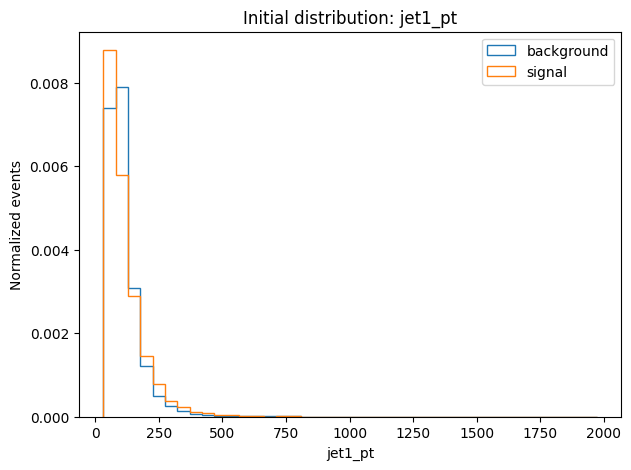

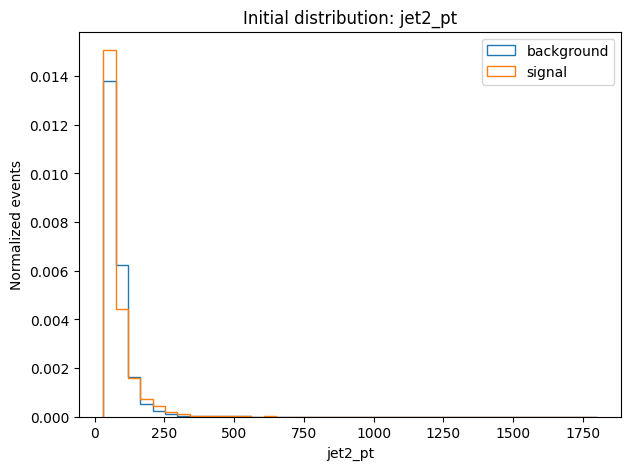

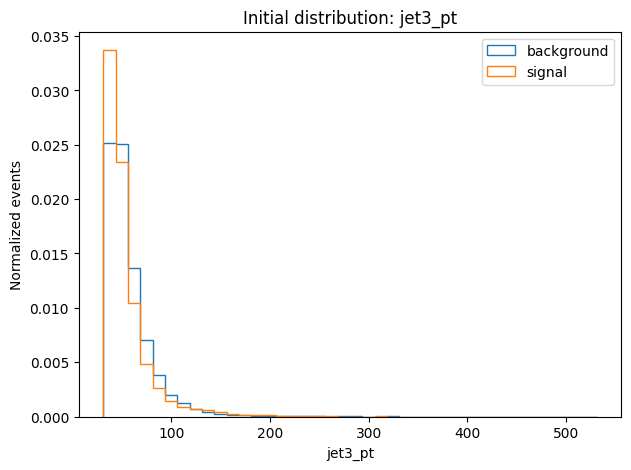

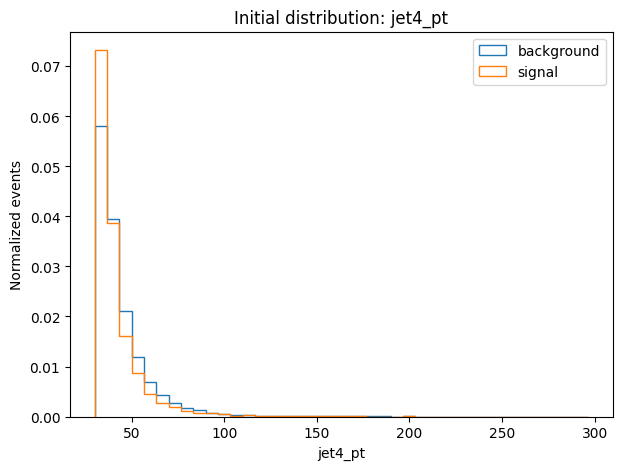

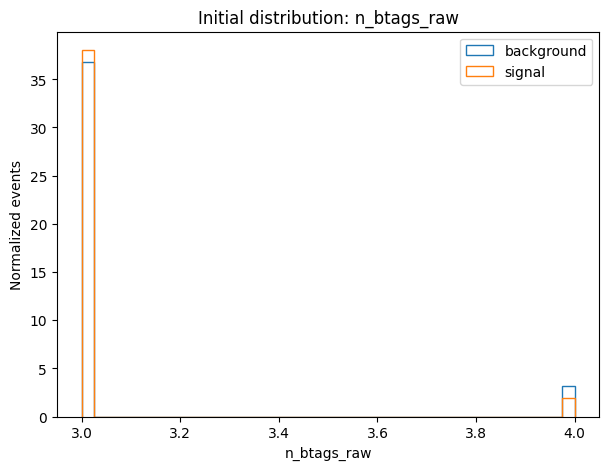

In [3]:
N_FILES_TO_USE = 24  # Original course configuration, preserving its sample comparison
print(f"Loading {N_FILES_TO_USE} EveNet files (up to {MAX_EVENTS:,} raw events).")
pipeline = load_physics_pipeline(
    n_files_to_use=N_FILES_TO_USE,
    max_events=MAX_EVENTS,
    random_state=RANDOM_STATE,
)

selected_events = pipeline["selected_events"]

display(pd.DataFrame({
    "raw_events_loaded": [len(pipeline["data"])],
    "selected_events": [len(selected_events)],
    "columns": [selected_events.shape[1]],
}))
display(selected_events.head())

selected_events["n_btags_raw"] = selected_events[[f"jet{i}_btag" for i in range(1, 5)]].sum(axis=1)
plot_columns = ["jet1_pt", "jet2_pt", "jet3_pt", "jet4_pt", "n_btags_raw"]
for column in plot_columns:
    values = selected_events[column].dropna().to_numpy()
    bins = np.histogram_bin_edges(values, bins=40)
    plt.figure()
    for label, name in [(0, "background"), (1, "signal")]:
        class_values = selected_events.loc[selected_events["label"] == label, column].dropna().to_numpy()
        plt.hist(class_values, bins=bins, histtype="step", density=True, label=name)
    plt.xlabel(column)
    plt.ylabel("Normalized events")
    plt.title(f"Initial distribution: {column}")
    plt.legend()
    plt.show()


## Section 2 - Feature Agent Template Class

The feature agent transforms the cleaned event dataframe into an ML-ready feature matrix. It keeps the direct four-jet measurements and adds derived physics variables that summarize the event topology.

Direct per-jet features:

- `jetN_pt`: transverse momentum of jet `N`.
- `jetN_eta`: pseudorapidity of jet `N`.
- `jetN_phi`: azimuthal angle of jet `N`.
- `jetN_mass`: reconstructed mass of jet `N`.
- `jetN_btag`: b-tag value for jet `N`; the code counts a jet as tagged when this value is at least 0.5.

Derived event features:

- `ht`: scalar sum of the four jet transverse momenta, $p_{T,1}+p_{T,2}+p_{T,3}+p_{T,4}$.
- `m_4j`: invariant mass of the four-jet system.
- `m_jj_12`, ..., `m_jj_34`: invariant masses of all six jet pairs.
- `deltaR_jj_12`, ..., `deltaR_jj_34`: angular separations between jet pairs, using $\Delta R = \sqrt{(\Delta\eta)^2 + (\Delta\phi)^2}$ with $\Delta\phi$ wrapped into $[-\pi, \pi]$.
- `min_deltaR_jj`: smallest pairwise jet separation in the event.
- `mean_deltaR_jj`: average pairwise jet separation in the event.
- `n_btags`: number of the four leading jets passing the b-tag threshold.

These variables encode the signal hypothesis. In $H \to aa \to b\bar{b}b\bar{b}$, the final state contains four b quarks, often organized into two pairs from the intermediate particles `a`. QCD background can also contain b jets, but its pair masses, angular structure, total activity, and b-tag multiplicity do not have to follow the same pattern.

In [4]:
# Fill in the feature construction inside FeatureAgent.
class FeatureAgent:
    def __init__(self, name="four_jet_feature_agent"):
        self.name = name
        self.X = None
        self.y = None

    @staticmethod
    def delta_phi(phi1, phi2):
        # Wrap the azimuthal difference into [-pi, pi).
        return (phi1 - phi2 + np.pi) % (2 * np.pi) - np.pi

    @staticmethod
    def four_vector(df, jet):
        pt = df[f"jet{jet}_pt"].astype(float)
        eta = df[f"jet{jet}_eta"].astype(float)
        phi = df[f"jet{jet}_phi"].astype(float)
        mass = df[f"jet{jet}_mass"].astype(float)

        # Collider coordinates (pt, eta, phi, m) -> Cartesian four-momentum (E, px, py, pz).
        px = pt * np.cos(phi)
        py = pt * np.sin(phi)
        pz = pt * np.sinh(eta)
        energy = np.sqrt(px**2 + py**2 + pz**2 + mass.clip(lower=0) ** 2)

        return pd.DataFrame({"E": energy, "px": px, "py": py, "pz": pz}, index=df.index)

    @staticmethod
    def invariant_mass(vectors):
        # Sum the four-vectors, then m^2 = E^2 - |p|^2 (clip tiny negative values from rounding).
        total = sum(vectors)
        mass2 = total["E"] ** 2 - total["px"] ** 2 - total["py"] ** 2 - total["pz"] ** 2
        return np.sqrt(mass2.clip(lower=0))

    def delta_r(self, df, i, j):
        d_eta = df[f"jet{i}_eta"].astype(float) - df[f"jet{j}_eta"].astype(float)
        d_phi = self.delta_phi(df[f"jet{i}_phi"].astype(float), df[f"jet{j}_phi"].astype(float))
        return np.sqrt(d_eta**2 + d_phi**2)

    def features(self, selected_events):
        df = selected_events.copy()
        X = pd.DataFrame(index=df.index)

        # Direct jet features: these are ready to use.
        for jet in range(1, 5):
            for field in ["pt", "eta", "phi", "mass", "btag"]:
                X[f"jet{jet}_{field}"] = df[f"jet{jet}_{field}"].astype(float)

        vectors = {jet: self.four_vector(df, jet) for jet in range(1, 5)}

        # Scalar sum of the four jet transverse momenta.
        X["ht"] = sum(df[f"jet{jet}_pt"].astype(float) for jet in range(1, 5))

        # Invariant mass of the full four-jet system (expected near m_H = 125 GeV for signal).
        X["m_4j"] = self.invariant_mass([vectors[jet] for jet in range(1, 5)])

        delta_r_values = []
        for i in range(1, 5):
            for j in range(i + 1, 5):
                # Dijet invariant mass (correct pairings should sit near m_a for signal).
                X[f"m_jj_{i}{j}"] = self.invariant_mass([vectors[i], vectors[j]])

                # Angular separation between jets i and j.
                X[f"deltaR_jj_{i}{j}"] = self.delta_r(df, i, j)
                delta_r_values.append(X[f"deltaR_jj_{i}{j}"])

        delta_r_table = pd.concat(delta_r_values, axis=1)

        X["min_deltaR_jj"] = delta_r_table.min(axis=1)

        X["mean_deltaR_jj"] = delta_r_table.mean(axis=1)

        # A jet counts as b-tagged when its b-tag value is at least 0.5.
        X["n_btags"] = sum((df[f"jet{jet}_btag"].astype(float) >= 0.5).astype(int) for jet in range(1, 5))

        y = df["label"].astype(int)
        assert np.isfinite(X.to_numpy()).all(), "Feature matrix contains NaN or infinite values. Finish the feature TODOs."
        self.X = X
        self.y = y
        return X, y

    def describe(self):
        n_events = len(self.X) if self.X is not None else 0
        n_features = self.X.shape[1] if self.X is not None else 0
        return f"FeatureAgent `{self.name}` built {n_features} ML features for {n_events:,} selected events."

feature_agent = FeatureAgent()
X, y = feature_agent.features(selected_events)
print(feature_agent.describe())
display(X.head())
display(y.value_counts().sort_index().rename("events"))

FeatureAgent `four_jet_feature_agent` built 37 ML features for 75,126 selected events.


,jet1_pt,jet1_eta,jet1_phi,jet1_mass,jet1_btag,jet2_pt,jet2_eta,jet2_phi,jet2_mass,jet2_btag,...,deltaR_jj_14,m_jj_23,deltaR_jj_23,m_jj_24,deltaR_jj_24,m_jj_34,deltaR_jj_34,min_deltaR_jj,mean_deltaR_jj,n_btags
0,93.664531,-0.087359,-2.475345,9.789335,1.0,80.338509,1.576945,0.333819,0.000000,0.0,...,1.716670,120.710389,3.074257,99.099525,2.141976,46.830577,1.519132,0.603378,2.053430,3
1,61.916652,0.902399,0.266193,0.000000,0.0,47.088154,0.198319,2.316577,8.675580,1.0,...,2.204155,71.265440,1.650255,35.390279,0.764843,55.624029,1.444049,0.764843,1.816284,3
2,67.839815,-0.506841,-1.267455,8.586977,1.0,62.954586,-2.280551,-0.061890,0.000000,1.0,...,2.944715,73.083284,1.387979,110.394894,2.592716,92.279513,2.580536,1.387979,2.501674,4
3,52.155311,0.724185,1.833906,1.579675,1.0,46.139782,-2.184562,-1.162588,0.000000,1.0,...,3.432688,99.805236,2.531520,59.121267,1.272149,74.137131,2.385067,1.272149,2.588918,3
4,73.618286,0.643026,1.586173,5.096674,1.0,70.661523,-0.555229,-2.147839,10.997287,1.0,...,2.332642,75.998871,1.044931,140.471465,2.786370,177.377298,3.456857,1.044931,2.399009,4


label
0    64345
1    10781
Name: events, dtype: int64

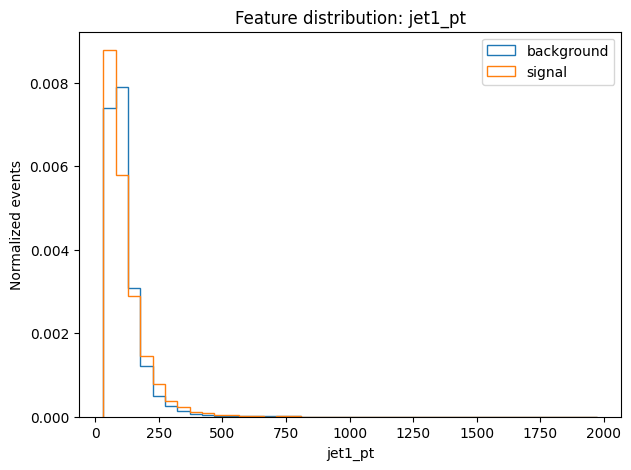

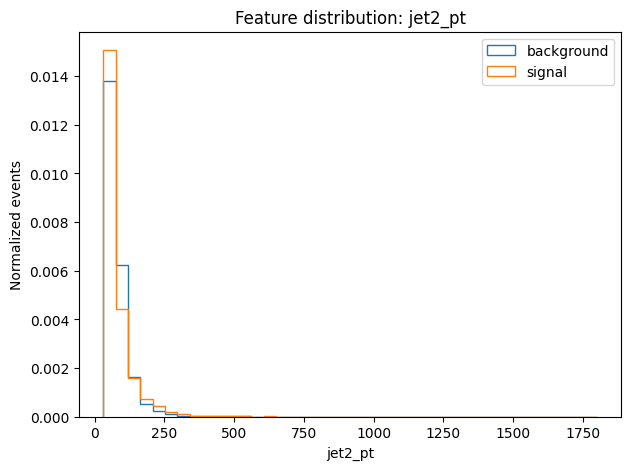

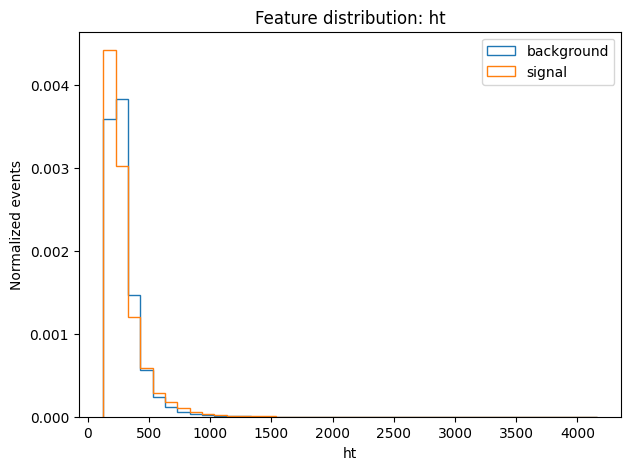

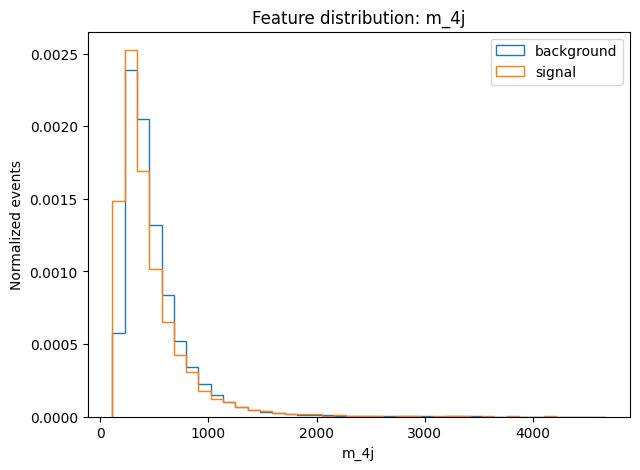

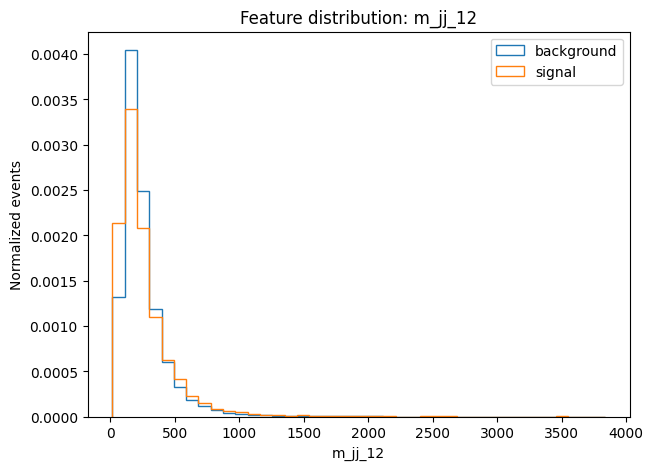

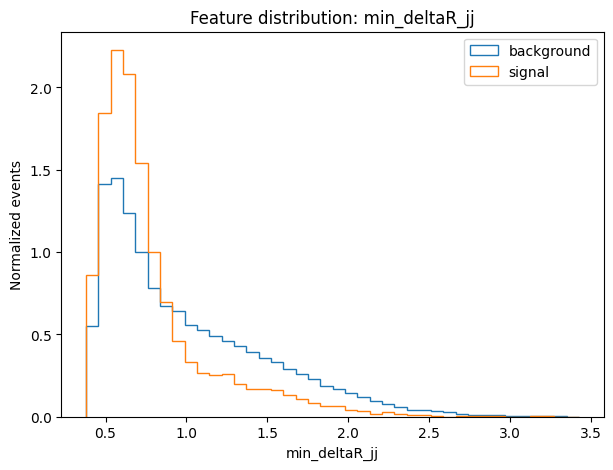

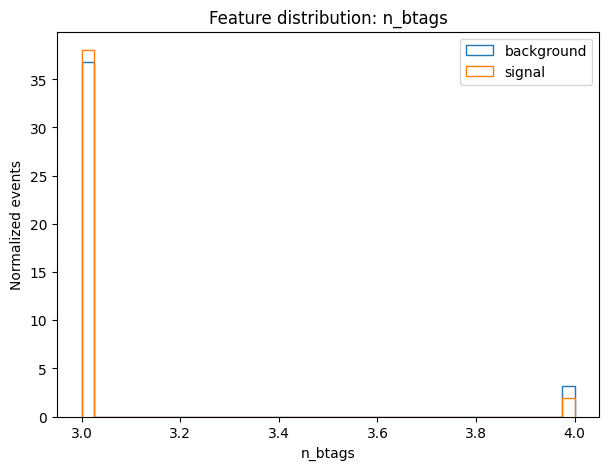

In [5]:
for feature in ["jet1_pt", "jet2_pt", "ht", "m_4j", "m_jj_12", "min_deltaR_jj", "n_btags"]:
    if feature not in X.columns:
        continue
    values = X[feature].dropna().to_numpy()
    bins = np.histogram_bin_edges(values, bins=40)
    plt.figure()
    plt.hist(X.loc[y == 0, feature], bins=bins, histtype="step", density=True, label="background")
    plt.hist(X.loc[y == 1, feature], bins=bins, histtype="step", density=True, label="signal")
    plt.xlabel(feature)
    plt.ylabel("Normalized events")
    plt.title(f"Feature distribution: {feature}")
    plt.legend()
    plt.show()


## Section 3 - Classification Agent Template Class

`ClassificationAgent` handles shared bookkeeping: feature selection, train/validation/test splitting, optional scaling, metric calculation, and text summaries.

The class handles shared bookkeeping and dispatches to the selected model family:

| Method | Input | Output |
| --- | --- | --- |
| `.train(X, y)` | feature dataframe and label series | fitted classification agent with metrics |
| `.predict(X_new)` | dataframe with the selected feature columns | signal-like score for each row |

Most of the classifier work happens here. The model library includes the random-forest baseline and four additional classifier families. Each model is trained and evaluated through the shared ClassificationAgent interface, allowing the PlanningAgent to propose different classification strategies and hyperparameters. The planning agent can then choose that `model_family`.

In [6]:
def baseline_strategy(feature_columns):
    return {
        "strategy_name": "baseline_random_forest",
        "rationale": "Baseline random forest using all engineered four-jet features.",
        "feature_columns": list(feature_columns),
        "model_family": "random_forest",
        "hyperparameters": {"n_estimators": 160, "min_samples_leaf": 2, "max_features": "sqrt"},
    }


# so ClassificationAgent.predict() can call predict_proba() on it like any other model.
class TorchMLPClassifier:
    def __init__(self, hidden_units=64, n_layers=2, dropout=0.1, learning_rate=1e-3,
                 epochs=15, batch_size=512, weight_decay=1e-5, random_state=RANDOM_STATE):
        self.hidden_units = hidden_units
        self.n_layers = n_layers
        self.dropout = dropout
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.weight_decay = weight_decay
        self.random_state = random_state
        self.network = None

    def _build(self, n_features):
        layers, width = [], n_features
        for _ in range(self.n_layers):
            layers += [nn.Linear(width, self.hidden_units), nn.ReLU(), nn.Dropout(self.dropout)]
            width = self.hidden_units
        layers.append(nn.Linear(width, 1))  # one output logit: large = signal-like
        return nn.Sequential(*layers)

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        X_t = torch.as_tensor(np.asarray(X, dtype=np.float32))
        y_t = torch.as_tensor(np.asarray(y, dtype=np.float32)).reshape(-1, 1)
        loader = DataLoader(TensorDataset(X_t, y_t), batch_size=self.batch_size, shuffle=True)

        self.network = self._build(X_t.shape[1])
        optimizer = torch.optim.Adam(self.network.parameters(), lr=self.learning_rate, weight_decay=self.weight_decay)
        loss_fn = nn.BCEWithLogitsLoss()  # binary cross-entropy on the raw logit

        self.network.train()
        for _ in range(self.epochs):
            for xb, yb in loader:
                optimizer.zero_grad()
                loss = loss_fn(self.network(xb), yb)
                loss.backward()
                optimizer.step()
        return self

    def predict_proba(self, X):
        self.network.eval()
        with torch.no_grad():
            logits = self.network(torch.as_tensor(np.asarray(X, dtype=np.float32)))
            p_signal = torch.sigmoid(logits).numpy().ravel()
        return np.column_stack([1.0 - p_signal, p_signal])


class ClassificationAgent:
    """Train and score one classifier chosen by a planning strategy.

    Add models in two places:
    1. Add a new entry to MODEL_LIBRARY.
    2. Add a new `elif self.model_family == "..."` block in train().

    predict() already works for scikit-learn classifiers with predict_proba.
    """

    MODEL_LIBRARY = {
        "random_forest": {
            "defaults": {"n_estimators": 160, "min_samples_leaf": 2, "max_depth": None, "max_features": "sqrt"},
            "allowed": {"n_estimators", "min_samples_leaf", "max_depth", "max_features"},
            "use_scaler": False,
        },
        "logistic_regression": {
            "defaults": {"C": 1.0, "max_iter": 1000},
            "allowed": {"C", "max_iter"},
            "use_scaler": True,
        },
        "extra_trees": {
            "defaults": {"n_estimators": 200, "min_samples_leaf": 2, "max_depth": None, "max_features": "sqrt"},
            "allowed": {"n_estimators", "min_samples_leaf", "max_depth", "max_features"},
            "use_scaler": False,
        },
        "hist_gradient_boosting": {
            "defaults": {"learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31, "min_samples_leaf": 20, "l2_regularization": 0.0},
            "allowed": {"learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf", "l2_regularization"},
            "use_scaler": False,
        },
        "mlp": {
            "defaults": {"hidden_units": 64, "n_layers": 2, "dropout": 0.1, "learning_rate": 1e-3, "epochs": 15, "batch_size": 512, "weight_decay": 1e-5},
            "allowed": {"hidden_units", "n_layers", "dropout", "learning_rate", "epochs", "batch_size", "weight_decay"},
            "use_scaler": True,
        },
    }

    def __init__(self, strategy=None, random_state=RANDOM_STATE):
        self.strategy = strategy
        self.random_state = random_state
        self.name = (strategy or {}).get("strategy_name", "classification_agent")
        self.model_family = (strategy or {}).get("model_family", "random_forest")
        self.feature_names_ = []
        self.hyperparameters = {}
        self.scaler = None
        self.model = None
        self.metrics = {}
        self.n_trained = 0

    @classmethod
    def catalog(cls):
        return {
            name: {
                "defaults": config["defaults"],
                "allowed": config["allowed"],
                "use_scaler": config["use_scaler"],
            }
            for name, config in cls.MODEL_LIBRARY.items()
        }

    def _config(self):
        if self.model_family not in self.MODEL_LIBRARY:
            raise ValueError(f"Unknown model_family {self.model_family!r}. Choose one of {list(self.MODEL_LIBRARY)}.")
        return self.MODEL_LIBRARY[self.model_family]

    def _clean_hyperparameters(self):
        config = self._config()
        params = config["defaults"].copy()
        for key, value in (self.strategy.get("hyperparameters", {}) or {}).items():
            if key in config["allowed"]:
                params[key] = value
        return params

    def _prepare_data(self, X, y):
        if self.strategy is None:
            self.strategy = baseline_strategy(X.columns)
        self.name = self.strategy.get("strategy_name", "classification_agent")
        self.model_family = self.strategy.get("model_family", "random_forest")
        requested = self.strategy.get("feature_columns", [])
        self.feature_names_ = [col for col in requested if col in X.columns and pd.api.types.is_numeric_dtype(X[col])]
        if not self.feature_names_:
            raise ValueError("Classifier strategy did not select any valid numeric feature columns.")
        self.hyperparameters = self._clean_hyperparameters()

        X_selected = X[self.feature_names_].copy()
        self.X_train, X_temp, self.y_train, y_temp = train_test_split(
            X_selected, y, test_size=0.40, stratify=y, random_state=self.random_state
        )
        self.X_val, self.X_test, self.y_val, self.y_test = train_test_split(
            X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=self.random_state
        )

        if self._config()["use_scaler"]:
            # Fit the scaler on training rows only, avoiding train/test leakage.
            self.scaler = StandardScaler()
            self.X_train_model = self.scaler.fit_transform(self.X_train)
        else:
            self.scaler = None
            self.X_train_model = self.X_train

    def _model_input(self, X):
        X_selected = X[self.feature_names_].copy()
        return self.scaler.transform(X_selected) if self.scaler is not None else X_selected

    def train(self, X, y):
        self._prepare_data(X, y)

        if self.model_family == "random_forest":
            params = self.hyperparameters.copy()
            params["n_estimators"] = int(np.clip(int(params.get("n_estimators", 160)), 50, 300))
            params["min_samples_leaf"] = int(np.clip(int(params.get("min_samples_leaf", 2)), 1, 20))
            if params.get("max_depth") is not None:
                params["max_depth"] = int(np.clip(int(params["max_depth"]), 2, 40))
            if params.get("max_features") not in ["sqrt", "log2", None]:
                params["max_features"] = "sqrt"
            self.model = RandomForestClassifier(random_state=self.random_state, n_jobs=-1, **params)
            self.model.fit(self.X_train_model, self.y_train)

        # Each block should set `params`, create `self.model`, and fit it on self.X_train_model.
        # Hyperparameters come from the LLM, so clip every value into a safe range before training.
        elif self.model_family == "logistic_regression":
            params = self.hyperparameters.copy()
            params["C"] = float(np.clip(float(params.get("C", 1.0)), 1e-4, 1e4))
            params["max_iter"] = int(np.clip(int(params.get("max_iter", 1000)), 100, 5000))
            self.model = LogisticRegression(random_state=self.random_state, **params)
            self.model.fit(self.X_train_model, self.y_train)

        elif self.model_family == "extra_trees":
            params = self.hyperparameters.copy()
            params["n_estimators"] = int(np.clip(int(params.get("n_estimators", 200)), 50, 300))
            params["min_samples_leaf"] = int(np.clip(int(params.get("min_samples_leaf", 2)), 1, 20))
            if params.get("max_depth") is not None:
                params["max_depth"] = int(np.clip(int(params["max_depth"]), 2, 40))
            if params.get("max_features") not in ["sqrt", "log2", None]:
                params["max_features"] = "sqrt"
            self.model = ExtraTreesClassifier(random_state=self.random_state, n_jobs=-1, **params)
            self.model.fit(self.X_train_model, self.y_train)

        elif self.model_family == "hist_gradient_boosting":
            params = self.hyperparameters.copy()
            params["learning_rate"] = float(np.clip(float(params.get("learning_rate", 0.1)), 0.01, 0.5))
            params["max_iter"] = int(np.clip(int(params.get("max_iter", 200)), 50, 500))
            params["max_leaf_nodes"] = int(np.clip(int(params.get("max_leaf_nodes", 31)), 8, 128))
            params["min_samples_leaf"] = int(np.clip(int(params.get("min_samples_leaf", 20)), 5, 200))
            params["l2_regularization"] = float(np.clip(float(params.get("l2_regularization", 0.0)), 0.0, 10.0))
            self.model = HistGradientBoostingClassifier(random_state=self.random_state, **params)
            self.model.fit(self.X_train_model, self.y_train)

        elif self.model_family == "mlp":
            params = self.hyperparameters.copy()
            params["hidden_units"] = int(np.clip(int(params.get("hidden_units", 64)), 8, 256))
            params["n_layers"] = int(np.clip(int(params.get("n_layers", 2)), 1, 4))
            params["dropout"] = float(np.clip(float(params.get("dropout", 0.1)), 0.0, 0.5))
            params["learning_rate"] = float(np.clip(float(params.get("learning_rate", 1e-3)), 1e-4, 1e-2))
            params["epochs"] = int(np.clip(int(params.get("epochs", 15)), 3, 40))
            params["batch_size"] = int(np.clip(int(params.get("batch_size", 512)), 64, 4096))
            params["weight_decay"] = float(np.clip(float(params.get("weight_decay", 1e-5)), 0.0, 1e-2))
            self.model = TorchMLPClassifier(random_state=self.random_state, **params)
            self.model.fit(self.X_train_model, self.y_train)


        else:
            raise ValueError(f"No training code is defined for model_family {self.model_family!r}.")

        self.hyperparameters = params
        self.n_trained += 1
        self.metrics["validation"] = self.evaluate(self.X_val, self.y_val)
        self.metrics["test"] = self.evaluate(self.X_test, self.y_test)
        return self

    def predict(self, X):
        scores = self.model.predict_proba(self._model_input(X))[:, 1]
        return np.clip(np.asarray(scores, dtype=float), 0.0, 1.0)

    def evaluate(self, X, y):
        scores = self.predict(X)
        predictions = (scores >= 0.5).astype(int)
        return {
            "accuracy": accuracy_score(y, predictions),
            "auc": roc_auc_score(y, scores),
            "confusion_matrix": confusion_matrix(y, predictions),
            "classification_report": classification_report(y, predictions, zero_division=0),
            "scores": scores,
        }

    def describe(self):
        val_auc = self.metrics.get("validation", {}).get("auc", np.nan)
        test_auc = self.metrics.get("test", {}).get("auc", np.nan)
        return (
            f"ClassificationAgent `{self.name}` trained `{self.model_family}` using {len(self.feature_names_)} features. "
            f"Validation AUC = {val_auc:.3f}; test AUC = {test_auc:.3f}. "
            f"Hyperparameters: {self.hyperparameters}."
        )


AGENT_CATALOG = ClassificationAgent.catalog()

baseline_classifier = ClassificationAgent(strategy=baseline_strategy(X.columns))
baseline_classifier.train(X, y)
baseline_scores = baseline_classifier.predict(baseline_classifier.X_test)
print(baseline_classifier.describe())

ClassificationAgent `baseline_random_forest` trained `random_forest` using 37 features. Validation AUC = 0.811; test AUC = 0.811. Hyperparameters: {'n_estimators': 160, 'min_samples_leaf': 2, 'max_depth': None, 'max_features': 'sqrt'}.


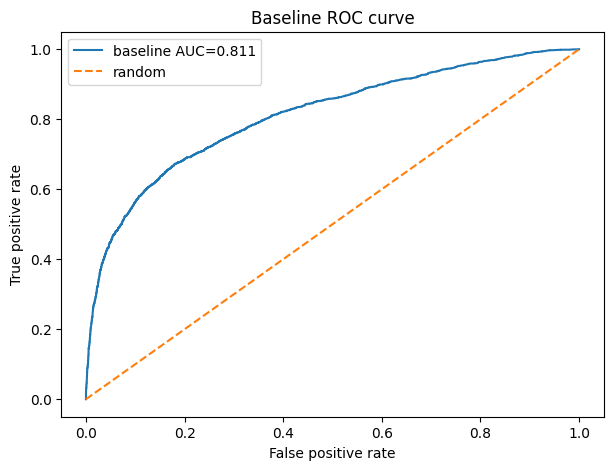

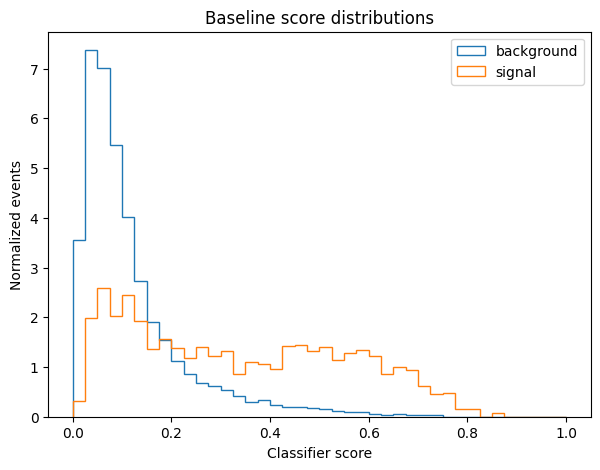

In [7]:
fpr, tpr, _ = roc_curve(baseline_classifier.y_test, baseline_scores)
plt.figure()
plt.plot(fpr, tpr, label=f"baseline AUC={baseline_classifier.metrics['test']['auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Baseline ROC curve")
plt.legend()
plt.show()

score_bins = np.linspace(0, 1, 41)
plt.figure()
plt.hist(baseline_scores[baseline_classifier.y_test.to_numpy() == 0], bins=score_bins, histtype="step", density=True, label="background")
plt.hist(baseline_scores[baseline_classifier.y_test.to_numpy() == 1], bins=score_bins, histtype="step", density=True, label="signal")
plt.xlabel("Classifier score")
plt.ylabel("Normalized events")
plt.title("Baseline score distributions")
plt.legend()
plt.show()


## Section 4 - Signal Analysis Agent Template Class

`SignalAnalysisAgent` turns classifier scores into a simple counting analysis.

The SignalAnalysisAgent scans classifier-score thresholds, counts the signal and background events passing each threshold, calculates the corresponding efficiencies, and evaluates the significance proxy \(S/\sqrt{B}\). For each threshold, select events with `scores >= threshold`, count selected signal and background events, compute efficiencies, and compute the counting significance $S/\sqrt{B}$.

,threshold,S,B,signal_efficiency,background_efficiency,S_over_sqrt_B
0,0.1,1784,5335,0.827458,0.414530,24.424610
1,0.2,1391,2055,0.645176,0.159674,30.684653
2,0.3,1111,995,0.515306,0.077312,35.221068
3,0.4,878,485,0.407236,0.037685,39.867926
4,0.5,600,227,0.278293,0.017638,39.823399
5,0.6,321,79,0.148887,0.006138,36.115322
6,0.7,104,19,0.048237,0.001476,23.859236
7,0.8,12,1,0.005566,0.000078,12.000000
8,0.9,0,0,0.000000,0.000000,NaN


SignalAnalysisAgent found the best threshold at score >= 0.40, with S/sqrt(B) = 39.87.


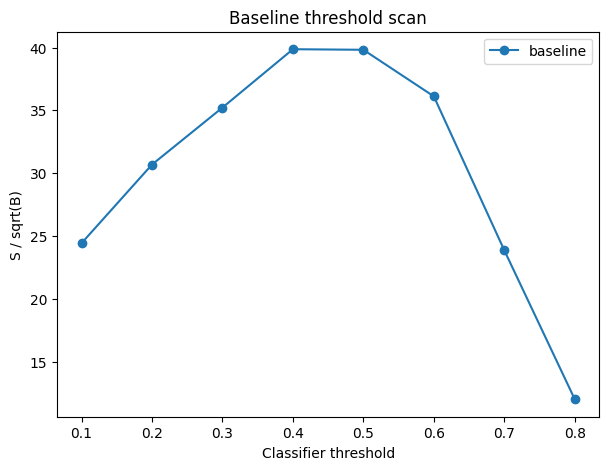

In [8]:
class SignalAnalysisAgent:
    def __init__(self, thresholds=None):
        self.thresholds = thresholds if thresholds is not None else np.arange(0.1, 1.0, 0.1)
        self.scan_table = None
        self.best = None

    def analyze(self, y_true, scores):
        y_true = pd.Series(y_true).astype(int).reset_index(drop=True)
        scores = np.asarray(scores, dtype=float)
        total_signal = max(int((y_true == 1).sum()), 1)
        total_background = max(int((y_true == 0).sum()), 1)
        rows = []

        # For each threshold:
        # - select events with scores >= threshold
        # - count selected signal events S
        # - count selected background events B
        # - compute signal efficiency S / total_signal
        # - compute background efficiency B / total_background
        # - compute counting significance S / sqrt(B)
        # - append one dictionary to rows with the columns used below
        if len(y_true) != len(scores):
            raise ValueError("Labels and classifier scores must have identical lengths.")
        if not np.isfinite(scores).all():
            raise ValueError("Non-finite classifier scores cannot be thresholded.")
        is_signal = (y_true == 1).to_numpy()
        for threshold in self.thresholds:
            selected = scores >= threshold
            S = int((selected & is_signal).sum())
            B = int((selected & ~is_signal).sum())
            rows.append({
                "threshold": float(threshold),
                "S": S,
                "B": B,
                "signal_efficiency": S / total_signal,
                "background_efficiency": B / total_background,
                # With B = 0, S/sqrt(B) is infinite and statistically meaningless, so record NaN.
                "S_over_sqrt_B": S / np.sqrt(B) if B > 0 else np.nan,
            })

        self.scan_table = pd.DataFrame(rows)
        if self.scan_table.empty:
            raise ValueError("Threshold scan is empty. Finish SignalAnalysisAgent.analyze(...).")
        self.best = self.scan_table.sort_values("S_over_sqrt_B", ascending=False, na_position="last").iloc[0]
        return self.scan_table, self.best

    def describe(self):
        return (
            f"SignalAnalysisAgent found the best threshold at score >= {self.best['threshold']:.2f}, "
            f"with S/sqrt(B) = {self.best['S_over_sqrt_B']:.2f}."
        )

signal_agent = SignalAnalysisAgent()
baseline_scan, baseline_best = signal_agent.analyze(baseline_classifier.y_test, baseline_scores)
display(baseline_scan)
print(signal_agent.describe())

plt.figure()
plt.plot(baseline_scan["threshold"], baseline_scan["S_over_sqrt_B"], marker="o", label="baseline")
plt.xlabel("Classifier threshold")
plt.ylabel("S / sqrt(B)")
plt.title("Baseline threshold scan")
plt.legend()
plt.show()

## Section 5 - Planning Agent Template Class

The planning agent reads previous round results and proposes the next classifier strategy. It does not write executable classifier code.

The API call, JSON parsing, and validation are fixed infrastructure. Edit `PLANNING_PROMPT` to direct the strategy: which features to try, which model families to prefer, how much to explore, and how to react to previous results.

Example planning-agent output:

```python
{
    "strategy_name": "extra_trees_mass_and_btag_scan",
    "rationale": "Try a high-capacity tree model using invariant-mass, angular-separation, and b-tag variables that match the four-b signal topology.",
    "feature_columns": [
        "ht",
        "m_4j",
        "m_jj_12",
        "m_jj_13",
        "m_jj_14",
        "m_jj_23",
        "m_jj_24",
        "m_jj_34",
        "min_deltaR_jj",
        "mean_deltaR_jj",
        "n_btags",
    ],
    "model_family": "extra_trees",
    "hyperparameters": {
        "n_estimators": 220,
        "min_samples_leaf": 1,
        "max_features": "sqrt"
    }
}
```

**This completed lab uses four unique non-baseline classifiers.** With a configured Gemini API key, the PlanningAgent uses Gemini 3.5 Flash-Lite to propose the next classifier strategy from the remaining available model families. Without a key, a clearly labeled rule-based planner permits debugging the physics and model portions locally; it must not be described as an LLM-run result.

In [9]:
PLANNING_PROMPT = """
Return exactly one valid JSON strategy for the next classifier attempt.
Include these five keys: strategy_name, rationale, feature_columns, model_family, hyperparameters.
Use ONLY feature names from the supplied feature list, a model family from the current
allowed catalog, and hyperparameter names permitted for that family.

Physics guidance:
- The target is H -> aa -> (bb)(bb) against QCD heavy-flavour background.
- Prefer physically meaningful discriminators: m_4j, the six m_jj_* masses,
  six deltaR_jj_* separations, min_deltaR_jj, mean_deltaR_jj, n_btags and ht.
- Also consider individual jets' pt, mass, eta, phi and btag, since a restricted
  feature set could discard discriminating information.

Planning rules:
- The four planning rounds must test four DIFFERENT model families, in addition to
  the baseline random forest. The allowed catalog automatically excludes used families.
- Prefer nonlinear ensembles initially, but explore the remaining available families.
- Use previous-round summaries to adjust feature coverage and hyperparameters.
- Try a full physics feature set unless there is a reason to restrict it; compare
  both AUC and S/sqrt(B) when judging results.
- Limit training cost: sensible estimator counts, moderate MLP depth and epochs.
- Never return placeholder JSON or executable code; provide one concrete plan.
- Each strategy_name must identify its model and be distinct from previous names.
""".strip()


class PlanningAgent:
    """An LLM-guided planner, with an explicitly labeled offline rule-based mode."""

    def __init__(self, prompt=PLANNING_PROMPT, model_templates=AGENT_CATALOG,
                 api_key=LLM_API_KEY, model_name=LLM_MODEL):
        self.prompt = prompt
        self.model_templates = model_templates
        self.api_key = api_key.strip()
        self.model_name = model_name
        self.last_plan = None
        self.mode = f"{LLM_PROVIDER.title()} LLM ({self.model_name})" if self.api_key else "rule-based (NO LLM API KEY)"

    def _offline_plan(self, dataset_summary):
        """Select a valid candidate from families not yet tried; for testing only."""
        preferred_order = [
            "hist_gradient_boosting", "extra_trees", "mlp", "logistic_regression"
        ]
        family = next((name for name in preferred_order if name in self.model_templates), None)
        if family is None:
            raise ValueError("No untried model family is available for a planning round.")

        # Use the complete feature set for a fair first comparison with the baseline.
        chosen_features = list(dataset_summary["feature_names"])
        params = self.model_templates[family]["defaults"].copy()
        if family == "hist_gradient_boosting":
            params.update({"max_iter": 170, "learning_rate": 0.08, "max_leaf_nodes": 31})
        elif family == "extra_trees":
            params.update({"n_estimators": 220, "min_samples_leaf": 1})
        elif family == "mlp":
            params.update({"hidden_units": 96, "n_layers": 2, "epochs": 16,
                           "learning_rate": 0.001, "batch_size": 512})
        elif family == "logistic_regression":
            params.update({"C": 1.0, "max_iter": 1200})
        return {
            "strategy_name": f"offline_{family}_all_features",
            "rationale": (
                "Deterministic offline strategy for verifying the complete workflow. "
                "A configured Gemini or OpenAI API key is required for LLM-based planning."
            ),
            "feature_columns": chosen_features,
            "model_family": family,
            "hyperparameters": params,
        }

    def plan(self, history, dataset_summary, baseline_summary):
        if self.api_key:
            self.last_plan = request_strategy_from_llm(
                prompt=self.prompt,
                history=history,
                dataset_summary=dataset_summary,
                baseline_summary=baseline_summary,
                model_templates=self.model_templates,
                api_key=self.api_key,
                model_name=self.model_name,
            )
        else:
            self.last_plan = self._offline_plan(dataset_summary)
        return self.last_plan

    def describe(self, plan=None):
        plan = plan or self.last_plan
        return (
            f"PlanningAgent [{self.mode}] proposed `{plan['strategy_name']}`: "
            f"a `{plan['model_family']}` strategy with {len(plan['feature_columns'])} "
            f"features. Rationale: {plan['rationale']}"
        )

    def summarize_round(self, round_id, plan, classifier_agent, best):
        summary = summarize_planning_round(round_id, plan, classifier_agent, best)
        summary["planner_mode"] = self.mode
        return summary


### Baseline Agentic Workflow

This cell runs the same agent sequence once without an LLM-planned strategy. It gives a baseline random-forest result to compare against later.

Inputs: `X`, `y`, and `baseline_classifier` from the previous sections.

Outputs: `baseline_summary`, `baseline_scan`, `baseline_best`, and diagnostic plots.

In [10]:
baseline_summary = {
    "model": baseline_classifier.name,
    "test_auc": baseline_classifier.metrics["test"]["auc"],
    "best_threshold": baseline_best["threshold"],
    "best_S_over_sqrt_B": baseline_best["S_over_sqrt_B"],
}
display(pd.DataFrame([baseline_summary]))


,model,test_auc,best_threshold,best_S_over_sqrt_B
0,baseline_random_forest,0.811073,0.4,39.867926


### Agentic Planning Loop

Complete the orchestration loop. The loop should pass information from one agent to the next, save each round result, and update `history` so the planning agent can react to previous attempts.

Each iteration executes the feature agent, requests a strategy, trains its chosen classifier, scans score thresholds, and appends that round's evidence to history. Four **different** alternatives are required, so the planner's allowed catalog is progressively narrowed. The LLM may choose their order and settings, rather than executing arbitrary code.

Planner mode: Gemini LLM (gemini-3.5-flash-lite)

Planning round 1 / 4
FeatureAgent `four_jet_feature_agent` built 37 ML features for 75,126 selected events.
PlanningAgent [Gemini LLM (gemini-3.5-flash-lite)] proposed `hist_grad_boost_comprehensive_physics`: a `hist_gradient_boosting` strategy with 37 features. Rationale: Employ a Histogram Gradient Boosting classifier with all kinematic masses, angular metrics, b-tag counts, and object momenta to maximize sensitivity to the four-b decay topology of exotic Higgs events.
ClassificationAgent `hist_grad_boost_comprehensive_physics` trained `hist_gradient_boosting` using 37 features. Validation AUC = 0.819; test AUC = 0.822. Hyperparameters: {'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 63, 'min_samples_leaf': 20, 'l2_regularization': 0.01}.
SignalAnalysisAgent found the best threshold at score >= 0.50, with S/sqrt(B) = 42.71.


,round,strategy,model_family,features_used,hyperparameters,test_auc,best_threshold,best_S_over_sqrt_B,rationale,planner_mode
0,1,hist_grad_boost_comprehensive_physics,hist_gradient_boosting,37,"{""l2_regularization"": 0.01, ""learning_rate"": 0...",0.821817,0.5,42.707782,Employ a Histogram Gradient Boosting classifie...,Gemini LLM (gemini-3.5-flash-lite)


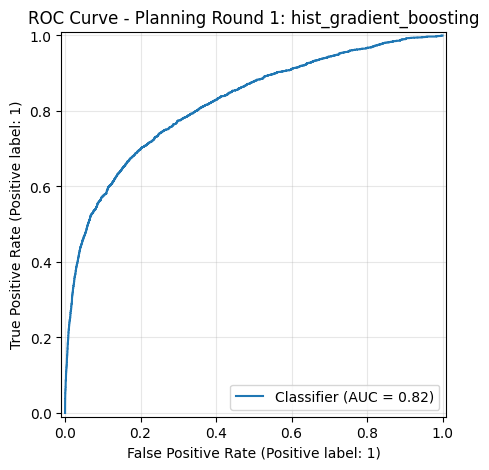

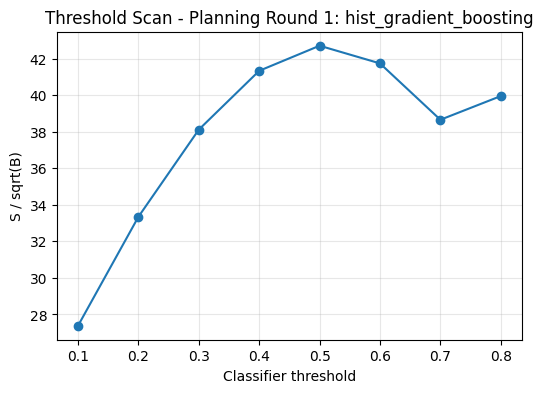


Planning round 2 / 4
FeatureAgent `four_jet_feature_agent` built 37 ML features for 75,126 selected events.
PlanningAgent [Gemini LLM (gemini-3.5-flash-lite)] proposed `extra_trees_full_physics`: a `extra_trees` strategy with 37 features. Rationale: Leverage an Extra Trees ensemble with all kinematic, angular, and b-tag features to capture multi-jet topology details for H->aa->4b decay.
ClassificationAgent `extra_trees_full_physics` trained `extra_trees` using 37 features. Validation AUC = 0.803; test AUC = 0.803. Hyperparameters: {'n_estimators': 250, 'min_samples_leaf': 2, 'max_depth': None, 'max_features': 'sqrt'}.
SignalAnalysisAgent found the best threshold at score >= 0.40, with S/sqrt(B) = 38.56.


,round,strategy,model_family,features_used,hyperparameters,test_auc,best_threshold,best_S_over_sqrt_B,rationale,planner_mode
0,1,hist_grad_boost_comprehensive_physics,hist_gradient_boosting,37,"{""l2_regularization"": 0.01, ""learning_rate"": 0...",0.821817,0.5,42.707782,Employ a Histogram Gradient Boosting classifie...,Gemini LLM (gemini-3.5-flash-lite)
1,2,extra_trees_full_physics,extra_trees,37,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",0.803171,0.4,38.556614,Leverage an Extra Trees ensemble with all kine...,Gemini LLM (gemini-3.5-flash-lite)


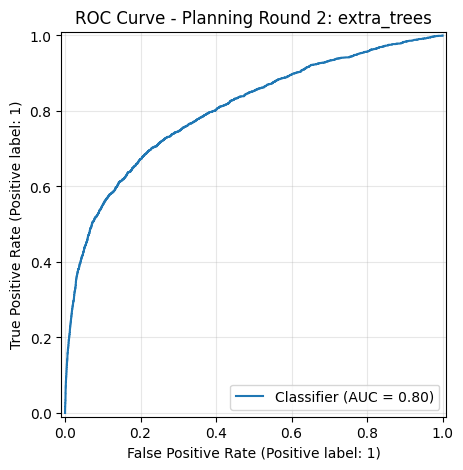

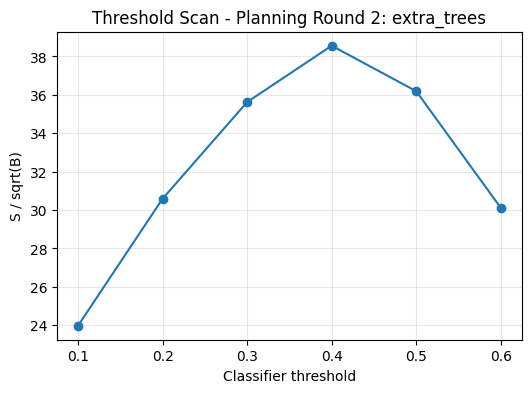


Planning round 3 / 4
FeatureAgent `four_jet_feature_agent` built 37 ML features for 75,126 selected events.
PlanningAgent [Gemini LLM (gemini-3.5-flash-lite)] proposed `mlp_comprehensive_physics`: a `mlp` strategy with 37 features. Rationale: Train a multi-layer perceptron on all available kinematic, angular, and b-tag features to capture complex non-linear correlations in the exotic four-b decay topology.
ClassificationAgent `mlp_comprehensive_physics` trained `mlp` using 37 features. Validation AUC = 0.793; test AUC = 0.794. Hyperparameters: {'hidden_units': 128, 'n_layers': 3, 'dropout': 0.15, 'learning_rate': 0.001, 'epochs': 20, 'batch_size': 256, 'weight_decay': 1e-05}.
SignalAnalysisAgent found the best threshold at score >= 0.60, with S/sqrt(B) = 34.71.


,round,strategy,model_family,features_used,hyperparameters,test_auc,best_threshold,best_S_over_sqrt_B,rationale,planner_mode
0,1,hist_grad_boost_comprehensive_physics,hist_gradient_boosting,37,"{""l2_regularization"": 0.01, ""learning_rate"": 0...",0.821817,0.5,42.707782,Employ a Histogram Gradient Boosting classifie...,Gemini LLM (gemini-3.5-flash-lite)
1,2,extra_trees_full_physics,extra_trees,37,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",0.803171,0.4,38.556614,Leverage an Extra Trees ensemble with all kine...,Gemini LLM (gemini-3.5-flash-lite)
2,3,mlp_comprehensive_physics,mlp,37,"{""batch_size"": 256, ""dropout"": 0.15, ""epochs"":...",0.793915,0.6,34.711319,Train a multi-layer perceptron on all availabl...,Gemini LLM (gemini-3.5-flash-lite)


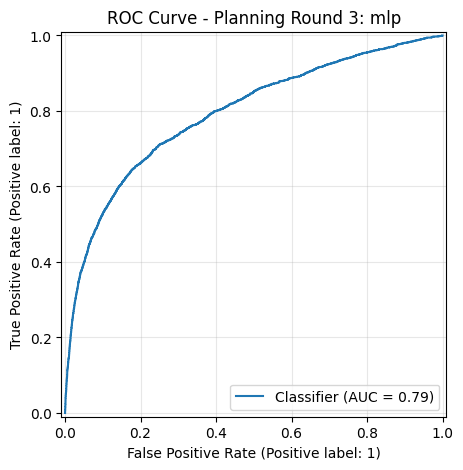

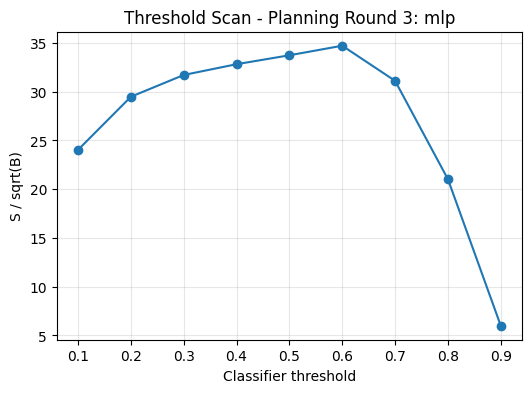


Planning round 4 / 4
FeatureAgent `four_jet_feature_agent` built 37 ML features for 75,126 selected events.
PlanningAgent [Gemini LLM (gemini-3.5-flash-lite)] proposed `logistic_regression_comprehensive_physics`: a `logistic_regression` strategy with 37 features. Rationale: Evaluate a linear decision boundary using all available kinematic, angular, and b-tag features with standard scaling to establish the linear baseline and explore coefficient-based feature importance for the exotic Higgs topology.
ClassificationAgent `logistic_regression_comprehensive_physics` trained `logistic_regression` using 37 features. Validation AUC = 0.702; test AUC = 0.702. Hyperparameters: {'C': 1.0, 'max_iter': 1000}.
SignalAnalysisAgent found the best threshold at score >= 0.20, with S/sqrt(B) = 20.85.


,round,strategy,model_family,features_used,hyperparameters,test_auc,best_threshold,best_S_over_sqrt_B,rationale,planner_mode
0,1,hist_grad_boost_comprehensive_physics,hist_gradient_boosting,37,"{""l2_regularization"": 0.01, ""learning_rate"": 0...",0.821817,0.5,42.707782,Employ a Histogram Gradient Boosting classifie...,Gemini LLM (gemini-3.5-flash-lite)
1,2,extra_trees_full_physics,extra_trees,37,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",0.803171,0.4,38.556614,Leverage an Extra Trees ensemble with all kine...,Gemini LLM (gemini-3.5-flash-lite)
2,3,mlp_comprehensive_physics,mlp,37,"{""batch_size"": 256, ""dropout"": 0.15, ""epochs"":...",0.793915,0.6,34.711319,Train a multi-layer perceptron on all availabl...,Gemini LLM (gemini-3.5-flash-lite)
3,4,logistic_regression_comprehensive_physics,logistic_regression,37,"{""C"": 1.0, ""max_iter"": 1000}",0.701941,0.2,20.853805,Evaluate a linear decision boundary using all ...,Gemini LLM (gemini-3.5-flash-lite)


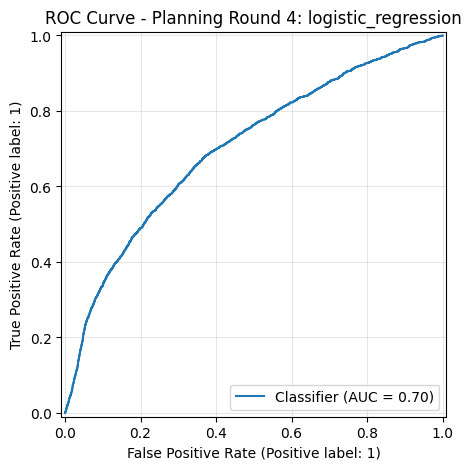

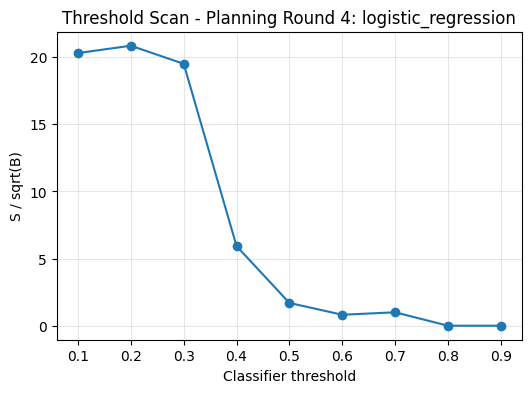

In [11]:
# Four DISTINCT additional classifier families, as required by the project slides.
CANDIDATE_FAMILIES = [
    "hist_gradient_boosting",
    "extra_trees",
    "mlp",
    "logistic_regression",
]
NUM_PLANNING_ROUNDS = len(CANDIDATE_FAMILIES)
history = []
planned_results = []
planning_agent = PlanningAgent()
tried_families = set()
print("Planner mode:", planning_agent.mode)

for round_id in range(1, NUM_PLANNING_ROUNDS + 1):
    print(f"\nPlanning round {round_id} / {NUM_PLANNING_ROUNDS}")

    # The feature-extraction agent constructs all physics observables from raw jets.
    feature_agent = FeatureAgent()
    X, y = feature_agent.features(selected_events)
    print(feature_agent.describe())

    # Pass only a compact summary to the planner (not full event-level data).
    dataset_summary = {
        "n_events": int(len(X)),
        "n_features": int(X.shape[1]),
        "class_counts": {"background": int((y == 0).sum()),
                         "signal": int((y == 1).sum())},
        "feature_names": list(X.columns),
    }

    # Restrict the planner's allowed catalog to families not previously tested.
    planning_agent.model_templates = {
        family: AGENT_CATALOG[family]
        for family in CANDIDATE_FAMILIES if family not in tried_families
    }

    # Retry an invalid JSON response from the LLM; never quietly conceal API errors.
    for attempt in range(3):
        try:
            plan = planning_agent.plan(
                history=history,
                dataset_summary=dataset_summary,
                baseline_summary=baseline_summary,
            )
            break
        except (ValueError, json.JSONDecodeError) as err:
            print(f"Invalid planning response (attempt {attempt + 1}/3): {err}")
    else:
        raise RuntimeError("The LLM did not produce a valid classifier plan in three tries.")

    if plan["model_family"] in tried_families:
        raise AssertionError("A model family was repeated despite the restricted catalog.")
    tried_families.add(plan["model_family"])
    print(planning_agent.describe(plan))

    # Train the classifier selected by the planning agent and assess ROC/AUC.
    classification_agent = ClassificationAgent(strategy=plan)
    classification_agent.train(X, y)
    scores = classification_agent.predict(classification_agent.X_test)
    print(classification_agent.describe())

    # Scan the professor's counting-significance proxy, S/sqrt(B).
    signal_agent = SignalAnalysisAgent()
    scan, best = signal_agent.analyze(classification_agent.y_test, scores)
    print(signal_agent.describe())

    # Retain the full result so the final cell can compare models and draw curves.
    planned_results.append({
        "round": round_id,
        "plan": plan,
        "agent": classification_agent,
        "scores": scores,
        "scan": scan,
        "best": best,
        "planner_mode": planning_agent.mode,
    })

    # Hand a compact result back to the planning agent for the next round.
    round_summary = planning_agent.summarize_round(
        round_id, plan, classification_agent, best
    )
    history.append(round_summary)
    display(pd.DataFrame(history))

    RocCurveDisplay.from_predictions(classification_agent.y_test, scores)
    plt.title(f"ROC Curve - Planning Round {round_id}: {plan['model_family']}")
    plt.grid(True, alpha=0.3)
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(scan["threshold"], scan["S_over_sqrt_B"], marker="o")
    plt.xlabel("Classifier threshold")
    plt.ylabel("S / sqrt(B)")
    plt.title(f"Threshold Scan - Planning Round {round_id}: {plan['model_family']}")
    plt.grid(True, alpha=0.3)
    plt.show()

assert len(planned_results) == 4
assert len({result['agent'].model_family for result in planned_results}) == 4


### Final Baseline versus Best Planned Model Comparison

This final comparison selects the planned model with the best threshold-scan value of $S/\sqrt{B}$, then compares it with the baseline random-forest workflow.

Baseline model:
ClassificationAgent `baseline_random_forest` trained `random_forest` using 37 features. Validation AUC = 0.811; test AUC = 0.811. Hyperparameters: {'n_estimators': 160, 'min_samples_leaf': 2, 'max_depth': None, 'max_features': 'sqrt'}.
Baseline best S/sqrt(B) = 39.87 at threshold 0.40.

Best planned model:
ClassificationAgent `hist_grad_boost_comprehensive_physics` trained `hist_gradient_boosting` using 37 features. Validation AUC = 0.819; test AUC = 0.822. Hyperparameters: {'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 63, 'min_samples_leaf': 20, 'l2_regularization': 0.01}.
Best planned S/sqrt(B) = 42.71 at threshold 0.50.
Planning rationale: Employ a Histogram Gradient Boosting classifier with all kinematic masses, angular metrics, b-tag counts, and object momenta to maximize sensitivity to the four-b decay topology of exotic Higgs events.
Features used (37): jet1_pt, jet1_eta, jet1_phi, jet1_mass, jet1_btag, jet2_pt, jet2_eta, jet2_phi, jet2_mass, jet2_bta

,model,strategy,model_family,features_used,test_auc,best_threshold,best_S_over_sqrt_B
0,baseline,baseline_random_forest,random_forest,37,0.811073,0.4,39.867926
1,best_planned,hist_grad_boost_comprehensive_physics,hist_gradient_boosting,37,0.821817,0.5,42.707782


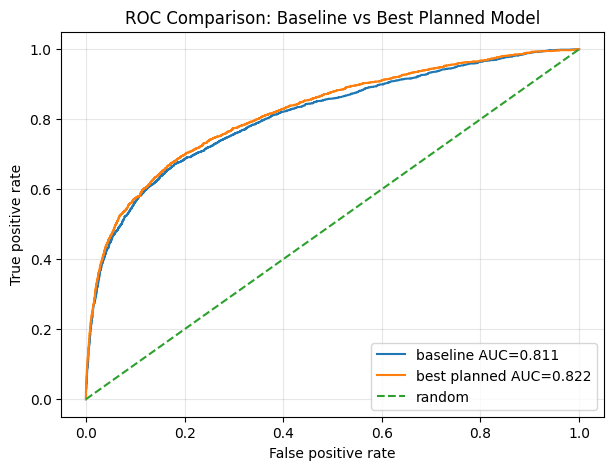

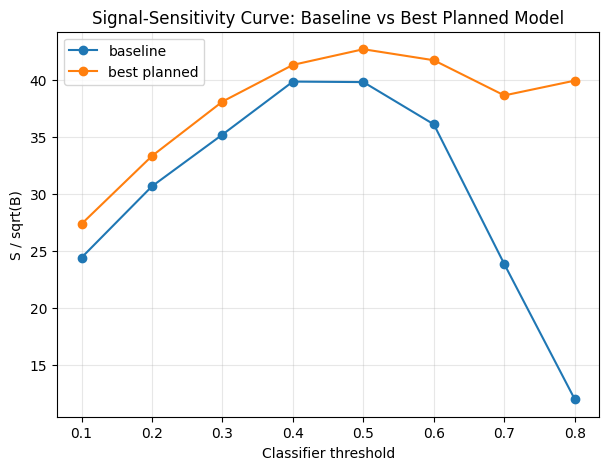


All models: random-forest baseline plus four distinct alternatives


,round,model_family,strategy_name,test_auc,best_threshold,best_S_over_sqrt_B,planner_mode
0,0,random_forest,baseline_random_forest,0.811073,0.4,39.867926,baseline (no planner)
1,1,hist_gradient_boosting,hist_grad_boost_comprehensive_physics,0.821817,0.5,42.707782,Gemini LLM (gemini-3.5-flash-lite)
2,2,extra_trees,extra_trees_full_physics,0.803171,0.4,38.556614,Gemini LLM (gemini-3.5-flash-lite)
3,3,mlp,mlp_comprehensive_physics,0.793915,0.6,34.711319,Gemini LLM (gemini-3.5-flash-lite)
4,4,logistic_regression,logistic_regression_comprehensive_physics,0.701941,0.2,20.853805,Gemini LLM (gemini-3.5-flash-lite)



Highest measured S/sqrt(B) = 42.71; target = 45
Target not reached on this sample. A larger independent-data study or tuning is needed.
Note: raw event counts and test-set threshold tuning do not constitute a discovery significance.


In [12]:
if not planned_results:
    raise RuntimeError("Run the Agentic Planning Loop before running this final comparison cell.")

best_result = max(planned_results, key=lambda result: result["best"]["S_over_sqrt_B"])
best_agent = best_result["agent"]
best_plan = best_result["plan"]
best_scan = best_result["scan"]
best_scores = best_result["scores"]

print("Baseline model:")
print(baseline_classifier.describe())
print(f"Baseline best S/sqrt(B) = {baseline_best['S_over_sqrt_B']:.2f} at threshold {baseline_best['threshold']:.2f}.")
print()

print("Best planned model:")
print(best_agent.describe())
print(
    f"Best planned S/sqrt(B) = {best_result['best']['S_over_sqrt_B']:.2f} "
    f"at threshold {best_result['best']['threshold']:.2f}."
)
print(f"Planning rationale: {best_plan['rationale']}")
print(f"Features used ({len(best_plan['feature_columns'])}): {', '.join(best_plan['feature_columns'])}")
print(f"Hyperparameters: {json.dumps(best_plan['hyperparameters'], sort_keys=True)}")

comparison = pd.DataFrame([
    {
        "model": "baseline",
        "strategy": baseline_classifier.name,
        "model_family": baseline_classifier.strategy["model_family"],
        "features_used": len(baseline_classifier.feature_names_),
        "test_auc": baseline_classifier.metrics["test"]["auc"],
        "best_threshold": baseline_best["threshold"],
        "best_S_over_sqrt_B": baseline_best["S_over_sqrt_B"],
    },
    {
        "model": "best_planned",
        "strategy": best_plan["strategy_name"],
        "model_family": best_plan["model_family"],
        "features_used": len(best_plan["feature_columns"]),
        "test_auc": best_agent.metrics["test"]["auc"],
        "best_threshold": best_result["best"]["threshold"],
        "best_S_over_sqrt_B": best_result["best"]["S_over_sqrt_B"],
    },
])
display(comparison)

baseline_fpr, baseline_tpr, _ = roc_curve(baseline_classifier.y_test, baseline_scores)
best_fpr, best_tpr, _ = roc_curve(best_agent.y_test, best_scores)

plt.figure(figsize=(7, 5))
plt.plot(baseline_fpr, baseline_tpr, label=f"baseline AUC={baseline_classifier.metrics['test']['auc']:.3f}")
plt.plot(best_fpr, best_tpr, label=f"best planned AUC={best_agent.metrics['test']['auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Comparison: Baseline vs Best Planned Model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(baseline_scan["threshold"], baseline_scan["S_over_sqrt_B"], marker="o", label="baseline")
plt.plot(best_scan["threshold"], best_scan["S_over_sqrt_B"], marker="o", label="best planned")
plt.xlabel("Classifier threshold")
plt.ylabel("S / sqrt(B)")
plt.title("Signal-Sensitivity Curve: Baseline vs Best Planned Model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# A full comparison is required: include every candidate, not just the winning one.
comparison_rows = [{
    "round": 0,
    "model_family": baseline_classifier.model_family,
    "strategy_name": baseline_classifier.name,
    "test_auc": float(baseline_classifier.metrics["test"]["auc"]),
    "best_threshold": float(baseline_best["threshold"]),
    "best_S_over_sqrt_B": float(baseline_best["S_over_sqrt_B"]),
    "planner_mode": "baseline (no planner)",
}]
for item in planned_results:
    comparison_rows.append({
        "round": item["round"],
        "model_family": item["agent"].model_family,
        "strategy_name": item["plan"]["strategy_name"],
        "test_auc": float(item["agent"].metrics["test"]["auc"]),
        "best_threshold": float(item["best"]["threshold"]),
        "best_S_over_sqrt_B": float(item["best"]["S_over_sqrt_B"]),
        "planner_mode": item["planner_mode"],
    })
all_models_comparison = pd.DataFrame(comparison_rows)
print("\nAll models: random-forest baseline plus four distinct alternatives")
display(all_models_comparison)

# Inspect observed values; never invent a significance higher than the achieved one.
TARGET_SIGNIFICANCE = 45.0
observed_significance = all_models_comparison["best_S_over_sqrt_B"].max()
print(f"\nHighest measured S/sqrt(B) = {observed_significance:.2f}; target = {TARGET_SIGNIFICANCE:.0f}")
if observed_significance >= TARGET_SIGNIFICANCE:
    print("The numerical target is reached on this sample, using the instructor's proxy.")
else:
    print("Target not reached on this sample. A larger independent-data study or tuning is needed.")
print("Note: raw event counts and test-set threshold tuning do not constitute a discovery significance.")


## Conclusions and Limitations

The completed pipeline follows the **FeatureAgent → PlanningAgent → ClassificationAgent → SignalAnalysisAgent** structure. The FeatureAgent prepared **37 four-jet physics observables** from **75,126 selected EveNet events** (drawn from a 200,000-event input subset). The PlanningAgent used **Gemini 3.5 Flash-Lite** to propose classification strategies, feature selections, and hyperparameters while considering the results of previous rounds. Four distinct classification models were evaluated in addition to the random-forest baseline.

### Model Performance Comparison

| Classifier | Test ROC AUC | Highest Scanned $S/\sqrt{B}$ |
|---|---:|---:|
| Random Forest (baseline) | 0.8111 | 39.87 |
| **Histogram Gradient Boosting** | **0.8218** | **42.71** |
| Extra Trees | 0.8032 | 38.56 |
| MLP Neural Network | 0.7939 | 34.71 |
| Logistic Regression | 0.7019 | 20.85 |

**Results:** Histogram Gradient Boosting achieved the best overall performance, outperforming the random-forest baseline in both test AUC (0.8218 versus 0.8111) and the significance metric (42.71 versus 39.87). This represents an approximately **7.1% improvement in $S/\sqrt{B}$**. The best significance was obtained at a classification threshold of 0.50, compared with 0.40 for the baseline. Although the numerical significance target of 45 was not achieved, the main objective of constructing a functioning four-agent pipeline, testing four additional classification models, and improving upon the baseline was accomplished.

**Interpretation:** The tree-based ensemble models generally performed better than Logistic Regression, suggesting that nonlinear relationships among jet momenta, invariant masses, angular separations, and b-tagging information are important for distinguishing exotic Higgs signal events from QCD background. Histogram Gradient Boosting was particularly effective at modeling these relationships. All four planned models used the full set of 37 physics features, so the observed performance differences primarily reflect the selected classifier families and their hyperparameters. However, these results depend on the particular dataset split and model configurations and do not establish that one classifier family is universally superior.

**Limitations:** The significance threshold was selected by maximizing $S/\sqrt{B}$ on the test set, which can introduce selection bias and produce an optimistic estimate. Additionally, the calculation uses unweighted simulated event counts without luminosity normalization or systematic uncertainties. Therefore, the reported significance is a simplified classroom metric rather than an experimental discovery significance. A more rigorous analysis would select thresholds using validation data and evaluate them on an independent test set.

**Reproducibility:** The notebook uses a fixed random seed (`RANDOM_STATE = 123`) for reproducible data splitting and model training. However, the LLM-based PlanningAgent may propose different strategies and hyperparameters on subsequent executions, as the planning process is not entirely deterministic. API credentials are stored separately in a local `.env` file and are not included in the submitted notebook.

Overall, this lab demonstrated how an LLM-guided agentic workflow can automate portions of a physics analysis, including feature extraction, classifier selection, model training, and performance evaluation. The workflow successfully improved upon the random-forest baseline while illustrating both the potential and limitations of agentic AI for scientific analysis.